# Classical pricing and risk references

Explore a European call under constant-parameter GBM. The notebook compares analytical prices and Greeks with independent Monte Carlo estimates, then examines parameter sensitivity, sampling uncertainty and spot-bump effects. A finite-difference solution adds a separate numerical price and Greek comparison, with space, time and boundary convergence studies.

Change the inputs below and **Run All** from a fresh kernel. All pricing, payoff and simulation calculations call `bsde_pricing`; the notebook organises experiments and presentation. The detailed derivations are in the [methodology](../docs/methodology.md).

In [1]:
from pathlib import Path
import html
import os
import platform
from dataclasses import replace

import numpy as np
import matplotlib
import scipy
import matplotlib.pyplot as plt
from IPython.display import HTML, display

# Support kernels launched from either the repository root or notebooks/.
cwd = Path.cwd()
root = next((p for p in (cwd, cwd.parent) if (p / "bsde_pricing").is_dir()), None)
if root is None:
    raise RuntimeError("Open the deep-bsde-pricing repository folder and restart the kernel.")
os.chdir(root)

from bsde_pricing.problems import GBMModel, EuropeanCall, PricingCase
from bsde_pricing.black_scholes import BlackScholesReference
from bsde_pricing.monte_carlo import MonteCarloPricer
from bsde_pricing.finite_difference import FiniteDifferencePricer

%matplotlib inline
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.2, "font.size": 10})

def table(headers, rows):
    heading = "".join(f"<th>{html.escape(str(v))}</th>" for v in headers)
    body = "".join("<tr>" + "".join(
        f"<td>{html.escape(format(v, '.7g') if isinstance(v, (float, np.floating)) else str(v))}</td>"
        for v in row) + "</tr>" for row in rows)
    display(HTML(f"<table><thead><tr>{heading}</tr></thead><tbody>{body}</tbody></table>"))

table(["Execution", "Version"], [("Python", platform.python_version()),
      ("NumPy", np.__version__), ("SciPy", scipy.__version__),
      ("Matplotlib", matplotlib.__version__)])

Execution,Version
Python,3.12.14
NumPy,2.3.5
SciPy,1.17.0
Matplotlib,3.10.8


## 1. Editable inputs

Rates use continuous compounding, maturity is in years, and volatility is annualised. Start by changing one financial input at a time. Seed and sample count control the numerical experiment rather than the option's economics.

The kernel must be the project's `bsde-pricing` environment. The default configuration is the previously verified vanilla case. The cells also work for other strictly positive spots/strikes and ordinary positive volatility/maturity settings.

In [2]:
spot = 100.0
strike = 100.0
rate = 0.03
dividend = 0.0
volatility = 0.20
maturity = 1.0

mc_paths = 100_000
seed = 2026
bump_fraction = 0.001
sample_counts = (1_000, 10_000, 100_000)
study_seeds = (2026, 2027, 2028, 2029)

case = PricingCase(
    "notebook_vanilla",
    GBMModel(rate, (volatility,), (dividend,), ((1.0,),)),
    EuropeanCall(strike, maturity), (spot,),
)
if volatility <= 0 or maturity <= 0:
    raise ValueError("The curve and delta studies require positive volatility and maturity.")
reference = BlackScholesReference(case.model, case.contract)
pricer = MonteCarloPricer(case.model, case.contract)
spot_grid = np.linspace(0.6 * strike, 1.4 * strike, 81)
base = reference.evaluate(spot)
table(["Input", "Value"], [("Spot", spot), ("Strike", strike), ("Rate", rate),
      ("Dividend yield", dividend), ("Volatility", volatility), ("Maturity", maturity),
      ("Monte Carlo samples", mc_paths), ("Seed", seed)])
table(["Call price", "Put price", "Call delta", "Gamma"],
      [(base.call_price, base.put_price, base.call_delta, base.gamma)])

Input,Value
Spot,100
Strike,100
Rate,0.03
Dividend yield,0
Volatility,0.2
Maturity,1
Monte Carlo samples,100000
Seed,2026


Call price,Put price,Call delta,Gamma
9.413403,6.457957,0.5987063,0.01933341


## 2. Price, delta and gamma across spot

Each curve holds contract and model parameters fixed while changing spot. Delta is the price slope; gamma is its curvature. The strike identifies the terminal-payoff kink, while a positive-volatility pre-expiry price is smooth.

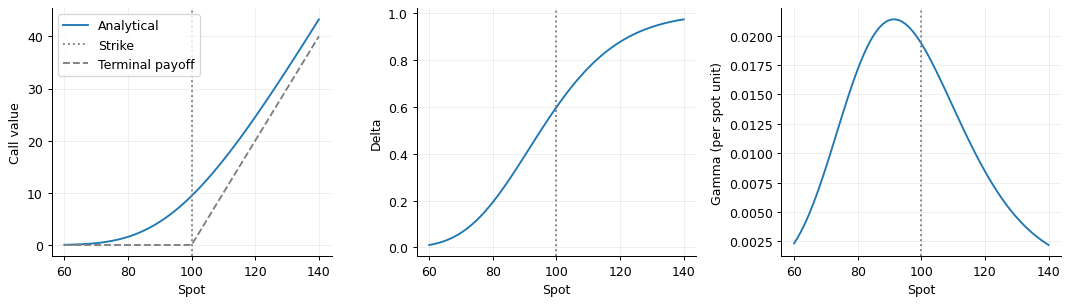

In [3]:
curve = [reference.evaluate(float(s)) for s in spot_grid]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, field, label in zip(axes, ("call_price", "call_delta", "gamma"),
                            ("Call value", "Delta", "Gamma (per spot unit)")):
    ax.plot(spot_grid, [getattr(v, field) for v in curve], color="C0", label="Analytical")
    ax.axvline(strike, color="0.5", ls=":", label="Strike")
    ax.set(xlabel="Spot", ylabel=label)
axes[0].plot(spot_grid, case.contract.payoff(spot_grid[:, None]),
             color="0.5", ls="--", label="Terminal payoff")
axes[0].legend()
fig.tight_layout()
plt.show()

## 3. Volatility, maturity, rates and dividends

The following grids are editable. They are selected one-parameter studies, not a full Cartesian search. A sensitivity plot shows how the model value changes; it does not measure pricing error.

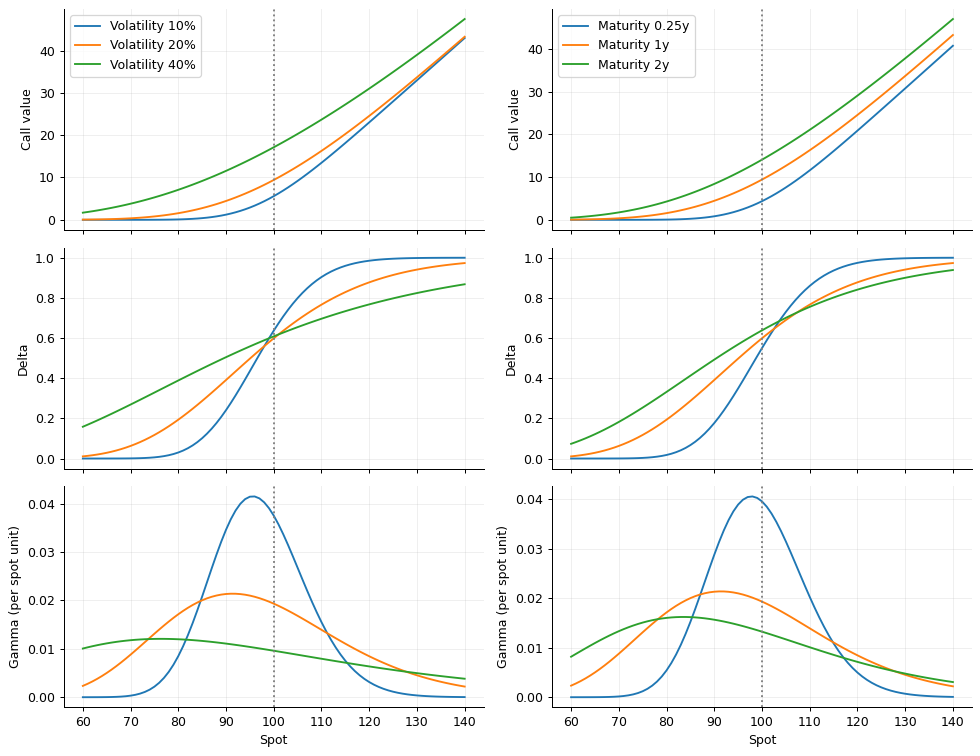

Changed input,Value,Call price,Delta,Gamma
Rate,-0.01,7.513058,0.5199388,0.0199222
Rate,0.03,9.413403,0.5987063,0.01933341
Rate,0.06,10.98955,0.6554217,0.01841351
Dividend,0,9.413403,0.5987063,0.01933341
Dividend,0.02,8.266328,0.5485365,0.01933341


In [4]:
volatility_values = (0.10, 0.20, 0.40)
maturity_values = (0.25, 1.0, 2.0)
rate_values = (-0.01, 0.03, 0.06)
dividend_values = (0.0, 0.02)

fig, axes = plt.subplots(3, 2, figsize=(11, 8.5), sharex=True)
for column, values in enumerate((volatility_values, maturity_values)):
    for value in values:
        model = replace(case.model, volatilities=(value,)) if column == 0 else case.model
        contract = case.contract if column == 0 else replace(case.contract, maturity=value)
        engine = BlackScholesReference(model, contract)
        results = [engine.evaluate(float(s)) for s in spot_grid]
        label = f"Volatility {value:.0%}" if column == 0 else f"Maturity {value:g}y"
        for row, field in enumerate(("call_price", "call_delta", "gamma")):
            axes[row, column].plot(spot_grid, [getattr(v, field) for v in results], label=label)
for row, label in enumerate(("Call value", "Delta", "Gamma (per spot unit)")):
    for column in range(2):
        axes[row, column].set_ylabel(label)
        axes[row, column].axvline(strike, color="0.5", ls=":")
axes[0, 0].legend()
axes[0, 1].legend()
axes[2, 0].set_xlabel("Spot")
axes[2, 1].set_xlabel("Spot")
fig.tight_layout()
plt.show()

rows = []
for name, values in (("Rate", rate_values), ("Dividend", dividend_values)):
    for value in values:
        model = replace(case.model, rate=value) if name == "Rate" else replace(
            case.model, dividend_yields=(value,))
        result = BlackScholesReference(model, case.contract).evaluate(spot)
        rows.append((name, value, result.call_price, result.call_delta, result.gamma))
table(["Changed input", "Value", "Call price", "Delta", "Gamma"], rows)

## 4. Monte Carlo estimates against analytical curves

Error bars are pointwise approximate 95% intervals. Identical seeds across spot values provide matched random draws, so estimates across those points are correlated. A single interval may miss the analytical value without establishing an implementation defect. Gamma remains an analytical reference here.

Spot,Analytical price,MC price,Price SE,Analytical delta,MC delta,Delta SE
80,1.561679,1.543293,0.0168826,0.1933225,0.1915088,0.00149621
100,9.413403,9.389657,0.04441069,0.5987063,0.5998578,0.001849228
120,24.54721,24.51982,0.06961492,0.8773026,0.8770123,0.001344414


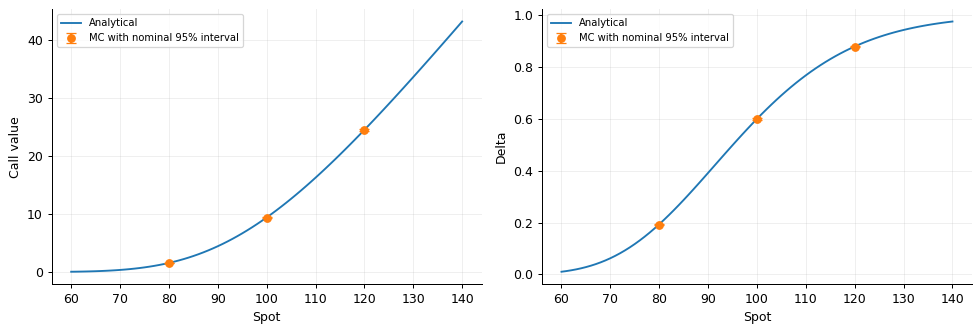

In [5]:
comparison_spots = sorted(set((0.8 * strike, spot, 1.2 * strike)))
comparisons = []
for s in comparison_spots:
    price = pricer.estimate((s,), n_paths=mc_paths, rng=np.random.default_rng(seed))
    delta = pricer.estimate_delta((s,), n_paths=mc_paths, rng=np.random.default_rng(seed),
                                  bump_fraction=bump_fraction)
    exact = reference.evaluate(s)
    comparisons.append((s, price, delta, exact))
table(["Spot", "Analytical price", "MC price", "Price SE", "Analytical delta", "MC delta", "Delta SE"],
      [(s, e.call_price, p.price_estimate, p.standard_error, e.call_delta,
        d.pathwise.estimate, d.pathwise.standard_error) for s, p, d, e in comparisons])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(spot_grid, [v.call_price for v in curve], label="Analytical")
axes[1].plot(spot_grid, [v.call_delta for v in curve], label="Analytical")
for ax, quantity in zip(axes, ("price", "delta")):
    means = [p.price_estimate if quantity == "price" else d.pathwise.estimate
             for s, p, d, e in comparisons]
    errors = [1.95996398454 * (p.standard_error if quantity == "price" else d.pathwise.standard_error)
              for s, p, d, e in comparisons]
    ax.errorbar(comparison_spots, means, yerr=errors, fmt="o", capsize=4,
                color="C1", label="MC with nominal 95% interval")
    ax.set(xlabel="Spot", ylabel="Call value" if quantity == "price" else "Delta")
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## 5. Sample count and seed variation

Standard error is expected to scale as $N^{-1/2}$. The dashed guides are anchored at the first measured point; they are not fitted convergence claims. RMS errors from four seeds are noisy summaries. Individual realised errors need not decrease monotonically as sample count increases.

Samples,Mean MC price,Price RMS error,Mean price SE,Delta RMS error,Mean delta SE
1000,9.632195,0.4508321,0.4596108,0.01592718,0.01866222
10000,9.41804,0.1351961,0.1412066,0.007116857,0.00585949
100000,9.407147,0.03369794,0.04459171,0.00290543,0.001851327


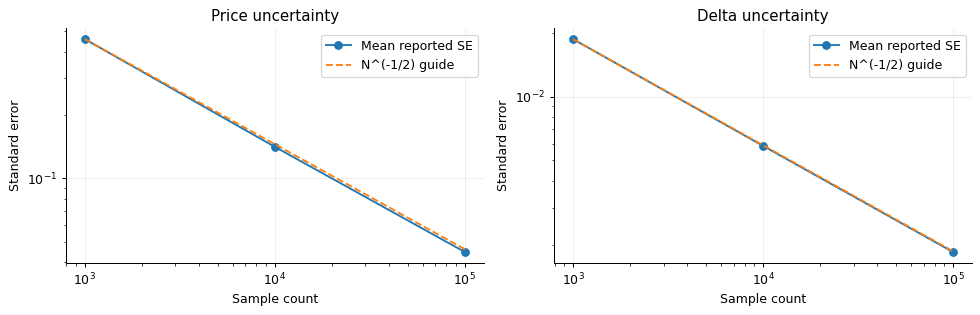

In [6]:
convergence = []
for count in sample_counts:
    prices, deltas = [], []
    for study_seed in study_seeds:
        prices.append(pricer.estimate((spot,), n_paths=count,
                      rng=np.random.default_rng(study_seed)))
        deltas.append(pricer.estimate_delta((spot,), n_paths=count,
                      rng=np.random.default_rng(study_seed), bump_fraction=bump_fraction))
    convergence.append((count,
        float(np.mean([v.price_estimate for v in prices])),
        float(np.sqrt(np.mean([(v.price_estimate - base.call_price)**2 for v in prices]))),
        float(np.mean([v.standard_error for v in prices])),
        float(np.sqrt(np.mean([(v.pathwise.estimate - base.call_delta)**2 for v in deltas]))),
        float(np.mean([v.pathwise.standard_error for v in deltas]))))
table(["Samples", "Mean MC price", "Price RMS error", "Mean price SE", "Delta RMS error", "Mean delta SE"], convergence)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
counts = np.array([row[0] for row in convergence])
for ax, index, title in zip(axes, (3, 5), ("Price uncertainty", "Delta uncertainty")):
    errors = np.array([row[index] for row in convergence])
    ax.loglog(counts, errors, "o-", label="Mean reported SE")
    ax.loglog(counts, errors[0] * np.sqrt(counts[0] / counts), "--", label="N^(-1/2) guide")
    ax.set(xlabel="Sample count", ylabel="Standard error", title=title)
    ax.legend()
fig.tight_layout()
plt.show()

## 6. Bump size and paired delta error

Pathwise and central-bump deltas share noise. Their discrepancy must use paired contributions, not an independent-error formula. A finite bump targets a price secant and introduces bias. The analytical derivative-minus-secant is therefore shown alongside the measured paired difference. Small crossing counts can make a normal interval unreliable; very small bumps also introduce rounding error.

Relative bump,Absolute bump,Pathwise,Central bump,Paired gap,Paired SE,Crossings
0.02,2,0.5998578,0.5990007,0.0008570958,0.0002502561,7991
0.01,1,0.5998578,0.5994556,0.000402132,0.0001769911,3969
0.005,0.5,0.5998578,0.5997778,7.999291e-05,0.0001261742,1963
0.001,0.1,0.5998578,0.5998742,-1.639589e-05,5.798102e-05,424


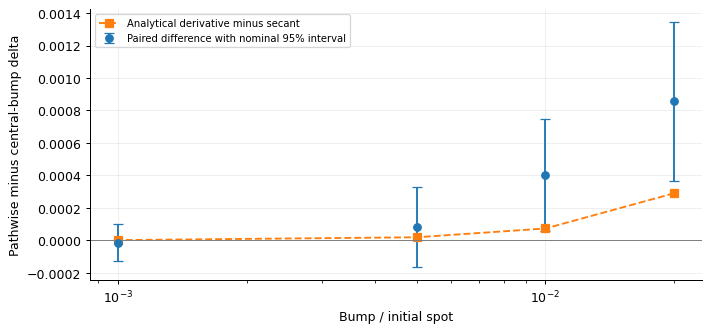

In [7]:
bump_fractions = (0.02, 0.01, 0.005, 0.001)
bump_results, expected_gaps = [], []
for fraction in bump_fractions:
    result = pricer.estimate_delta((spot,), n_paths=mc_paths,
             rng=np.random.default_rng(seed), bump_fraction=fraction)
    h = result.bump_size
    secant = (reference.evaluate(spot + h).call_price -
              reference.evaluate(spot - h).call_price) / (2 * h)
    bump_results.append(result)
    expected_gaps.append(base.call_delta - secant)
table(["Relative bump", "Absolute bump", "Pathwise", "Central bump", "Paired gap", "Paired SE", "Crossings"],
      [(v.bump_fraction, v.bump_size, v.pathwise.estimate, v.central_bump.estimate,
        v.paired_difference.estimate, v.paired_difference.standard_error,
        v.bump_crossing_count) for v in bump_results])
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.errorbar(bump_fractions, [v.paired_difference.estimate for v in bump_results],
    yerr=[1.95996398454 * v.paired_difference.standard_error for v in bump_results],
    fmt="o", capsize=4, label="Paired difference with nominal 95% interval")
ax.plot(bump_fractions, expected_gaps, "s--", label="Analytical derivative minus secant")
ax.axhline(0, color="0.5", lw=0.8)
ax.set(xscale="log", xlabel="Bump / initial spot", ylabel="Pathwise minus central-bump delta")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## 7. Finite-difference price and Greeks

With remaining time $\tau=T-t$, the pricing PDE is

$$u_\tau=\tfrac12\sigma^2S^2u_{SS}+(r-q)Su_S-ru,\qquad u(S,0)=(S-K)^+.$$

The finite domain has boundaries $u(0,\tau)=0$ and $u(S_{\max},\tau)\approx S_{\max}e^{-q\tau}-Ke^{-r\tau}$. The upper condition is an approximation, so it requires its own convergence check. Central spot differences give a tridiagonal system. When drift dominates near zero, the solver uses a one-sided spatial derivative on affected rows and reports their count. This local change is first order; the default case needs no such rows.

Crank–Nicolson averages the spatial operator across successive time levels. The first two full time intervals are each replaced by two backward-Euler half steps to damp the payoff kink, giving four startup solves. No analytical prices enter the solver. Delta and gamma use central differences of its grid values. Off-grid evaluation interpolates these nodal Greeks separately from prices.

The full derivation, matrix coefficients and supported scope are in the [methodology](../docs/methodology.md#finite-difference-reference). Price errors use the option's currency unit; delta errors are dimensionless and gamma errors are per unit of spot.

Grid setting,Value
Upper spot boundary,400
Spot intervals,400
Time intervals,400
Spot spacing,1
Rannacher intervals,2
One-sided spatial rows,0


Quantity,PDE,Analytical,Signed error
Call price,9.41095,9.413403,-0.002453315
Delta,0.5986522,0.5987063,-5.409283e-05
Gamma,0.01934023,0.01933341,6.825058e-06


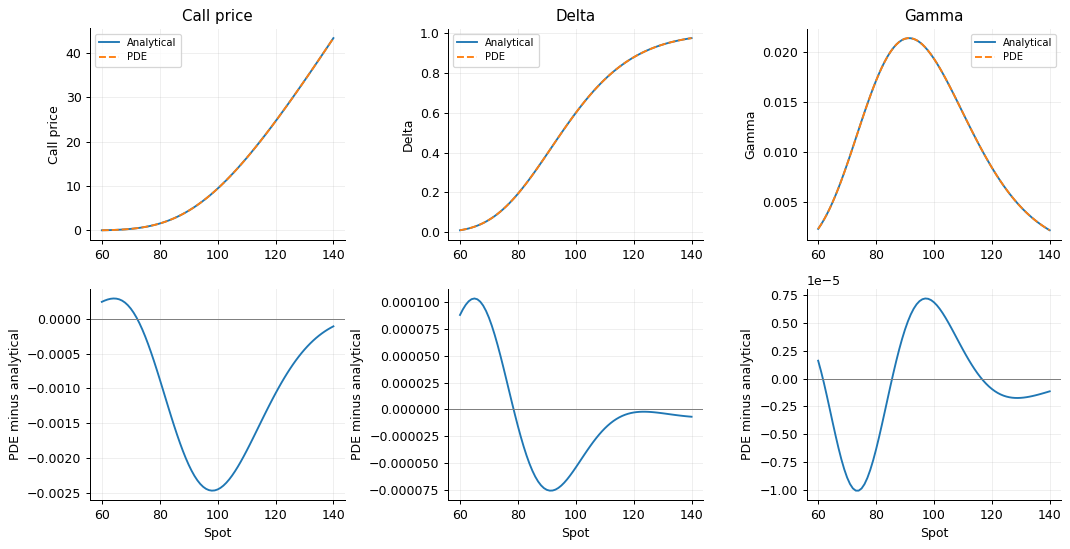

In [8]:
pde_s_max = 4.0 * strike
pde_space_steps = 400
pde_time_steps = 400
pde_rannacher_steps = 2

pde_pricer = FiniteDifferencePricer(case.model, case.contract)
pde = pde_pricer.solve(s_max=pde_s_max, n_space=pde_space_steps,
                      n_time=pde_time_steps, rannacher_steps=pde_rannacher_steps)
pde_at_spot = pde.evaluate(spot)
fields = ("call_price", "call_delta", "gamma")
labels = ("Call price", "Delta", "Gamma")
table(["Grid setting", "Value"], [("Upper spot boundary", pde_s_max),
      ("Spot intervals", pde_space_steps), ("Time intervals", pde_time_steps),
      ("Spot spacing", pde.spots[1]), ("Rannacher intervals", pde_rannacher_steps),
      ("One-sided spatial rows", pde.upwind_node_count)])
table(["Quantity", "PDE", "Analytical", "Signed error"],
      [(label, getattr(pde_at_spot, field), getattr(base, field),
        getattr(pde_at_spot, field) - getattr(base, field))
       for label, field in zip(labels, fields)])
pde_curve = [pde.evaluate(s) for s in spot_grid]
exact_curve = [reference.evaluate(s) for s in spot_grid]
fig, axes = plt.subplots(2, 3, figsize=(12, 6.2))
for j, (field, label) in enumerate(zip(fields, labels)):
    exact = np.array([getattr(v, field) for v in exact_curve])
    numerical = np.array([getattr(v, field) for v in pde_curve])
    axes[0, j].plot(spot_grid, exact, label="Analytical")
    axes[0, j].plot(spot_grid, numerical, "--", label="PDE")
    axes[0, j].set(ylabel=label, title=label)
    axes[0, j].legend(fontsize=8)
    axes[1, j].plot(spot_grid, numerical - exact)
    axes[1, j].axhline(0, color="0.5", lw=0.8)
    axes[1, j].set(xlabel="Spot", ylabel="PDE minus analytical")
fig.tight_layout()
plt.show()

## 8. Spatial refinement

Hold the upper boundary and a fine time grid fixed while doubling the number of spot intervals. Default spot and strike are nodes on every grid below. Off-grid interpolation or a strike falling between nodes can change observed error ratios. A factor-four reduction is evidence of second-order behaviour for this aligned case, rather than a promise for every input set.

The table separates signed errors from plotted absolute errors. Time and boundary errors eventually set a floor, so smaller spot spacing cannot improve accuracy indefinitely. The guide is anchored at the first measured price error, not fitted to later results.

Spot intervals,Spacing,Spot on grid,Strike on grid,Price error,Delta error,Gamma error
100,4,True,True,-0.03944984,-0.0008743534,0.0001110307
200,2,True,True,-0.009807322,-0.0002166111,2.730061e-05
400,1,True,True,-0.002448596,-5.403452e-05,6.798427e-06
800,0.5,True,True,-0.0006120794,-1.350292e-05,1.698694e-06


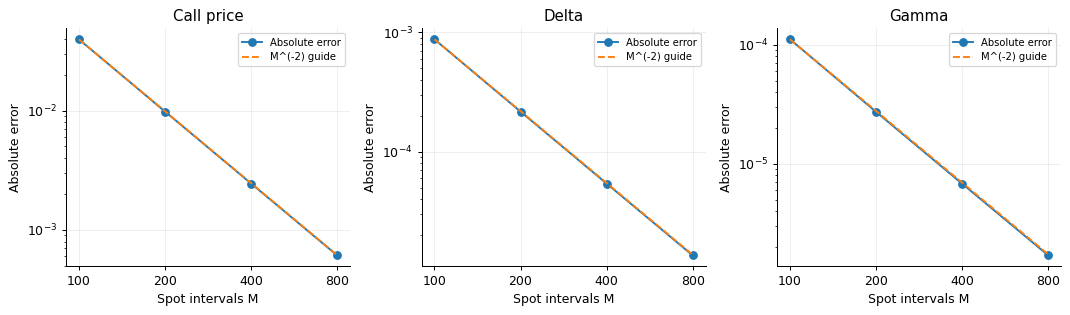

In [9]:
space_counts = (100, 200, 400, 800)
space_results = [pde_pricer.solve(s_max=pde_s_max, n_space=m, n_time=2048)
                 for m in space_counts]
space_values = [solution.evaluate(spot) for solution in space_results]
space_errors = np.array([[getattr(v, field) - getattr(base, field) for field in fields]
                         for v in space_values])
table(["Spot intervals", "Spacing", "Spot on grid", "Strike on grid", "Price error", "Delta error", "Gamma error"],
      [(m, v.spots[1], bool(np.isclose(spot / v.spots[1], round(spot / v.spots[1]))),
        bool(np.isclose(strike / v.spots[1], round(strike / v.spots[1]))), *errors)
       for m, v, errors in zip(space_counts, space_results, space_errors)])
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for j, label in enumerate(labels):
    errors = np.abs(space_errors[:, j])
    axes[j].loglog(space_counts, errors, "o-", label="Absolute error")
    axes[j].loglog(space_counts, errors[0] * (space_counts[0] / np.array(space_counts))**2,
                   "--", label="M^(-2) guide")
    axes[j].set(xlabel="Spot intervals M", ylabel="Absolute error", title=label)
    axes[j].set_xticks(space_counts, [str(v) for v in space_counts])
    axes[j].xaxis.set_minor_locator(matplotlib.ticker.NullLocator())
    axes[j].legend(fontsize=8)
fig.tight_layout()
plt.show()

## 9. Time refinement and the payoff kink

Hold the spatial grid at 800 intervals and vary the number of time intervals. Both methods use the same grid, payoff and boundaries. Plain Crank–Nicolson can preserve oscillations from the kink, especially in gamma. Rannacher startup reduces those oscillations; it does not make a coarse grid exact or guarantee nonnegative prices and gamma for all settings.

Errors below are against the analytical solution, so the curves include a fixed spatial error floor. Temporal convergence tests in the test suite additionally compare with a fine-time solution on the same spatial grid to isolate time error.

Method,Time intervals,Price error,Delta error,Gamma error
Plain CN,8,-0.2262767,-0.002649865,1.377962
Plain CN,16,-0.09008078,-0.0008420403,0.8472363
Plain CN,32,-0.01768522,-5.027294e-06,0.2190866
Plain CN,64,-0.0007361989,-5.53195e-06,0.002739825
Plain CN,128,-0.0005965786,-1.330817e-05,1.50641e-06
Rannacher + CN,8,-0.01299464,-0.0001664709,8.121572e-05
Rannacher + CN,16,-0.003683698,-5.144315e-05,2.028062e-05
Rannacher + CN,32,-0.001378533,-2.296977e-05,6.221036e-06
Rannacher + CN,64,-0.0008034747,-1.586688e-05,2.789125e-06
Rannacher + CN,128,-0.0006597833,-1.409212e-05,1.967812e-06


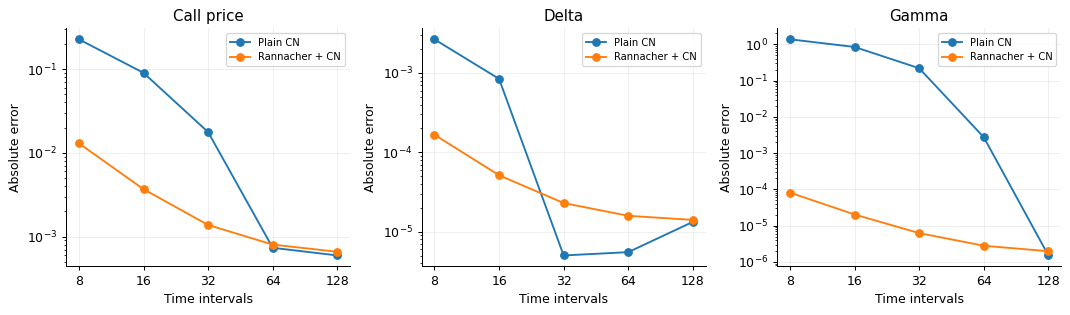

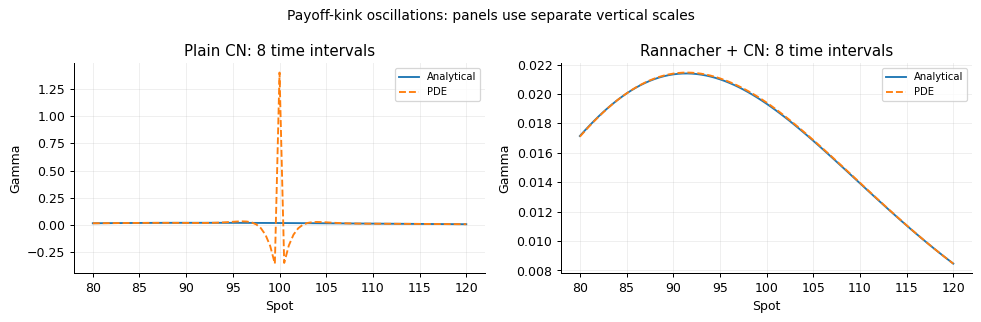

In [10]:
time_counts = (8, 16, 32, 64, 128)
time_solutions = {
    name: [pde_pricer.solve(s_max=pde_s_max, n_space=800, n_time=n,
                           rannacher_steps=startup) for n in time_counts]
    for name, startup in (("Plain CN", 0), ("Rannacher + CN", 2))
}
time_errors = {
    name: np.array([[getattr(solution.evaluate(spot), field) - getattr(base, field)
                     for field in fields] for solution in solutions])
    for name, solutions in time_solutions.items()
}
table(["Method", "Time intervals", "Price error", "Delta error", "Gamma error"],
      [(name, count, *errors) for name, values in time_errors.items()
       for count, errors in zip(time_counts, values)])
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for j, label in enumerate(labels):
    for name, errors in time_errors.items():
        axes[j].loglog(time_counts, np.abs(errors[:, j]), "o-", label=name)
    axes[j].set(xlabel="Time intervals", ylabel="Absolute error", title=label)
    axes[j].set_xticks(time_counts, [str(v) for v in time_counts])
    axes[j].xaxis.set_minor_locator(matplotlib.ticker.NullLocator())
    axes[j].legend(fontsize=8)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, (name, solutions) in zip(axes, time_solutions.items()):
    solution = solutions[0]
    nodes = solution.spots[1:-1]
    mask = (nodes >= 0.8 * strike) & (nodes <= 1.2 * strike)
    exact_gamma = [reference.evaluate(s).gamma for s in nodes[mask]]
    ax.plot(nodes[mask], exact_gamma, label="Analytical")
    ax.plot(nodes[mask], solution.gammas[mask], "--", label="PDE")
    ax.set(xlabel="Spot", ylabel="Gamma", title=f"{name}: 8 time intervals")
    ax.legend(fontsize=8)
fig.suptitle("Payoff-kink oscillations: panels use separate vertical scales", fontsize=11)
fig.tight_layout()
plt.show()

## 10. Upper boundary convergence

A wider domain at a fixed number of spot intervals also coarsens the mesh, confounding two effects. This experiment instead holds spot spacing at $K/200$, uses 800 time intervals, and increases the upper boundary. It evaluates at $S=K$ regardless of the editable initial spot, keeping the probe inside every domain. The smallest boundary is deliberately close to the strike.

The discounted linear boundary neglects the residual put value in put–call parity. Moving it out should reduce that error until space and time discretisation dominate. A plateau reflects the remaining mesh error; it does not establish accuracy across all maturities, volatilities or spots. Higher volatility and longer maturity can require a wider domain.

Boundary / strike,Upper boundary,Spot intervals,Spacing,Price error at S=K,Delta error,Gamma error
1.2,120,240,0.5,-0.2358629,-0.02892899,-0.002781014
1.6,160,320,0.5,-0.0006178435,-1.470283e-05,1.430175e-06
2,200,400,0.5,-0.0006131183,-1.351574e-05,1.704556e-06
3,300,600,0.5,-0.0006131183,-1.351575e-05,1.704555e-06
4,400,800,0.5,-0.0006131183,-1.351575e-05,1.704555e-06
6,600,1200,0.5,-0.0006131183,-1.351575e-05,1.704555e-06


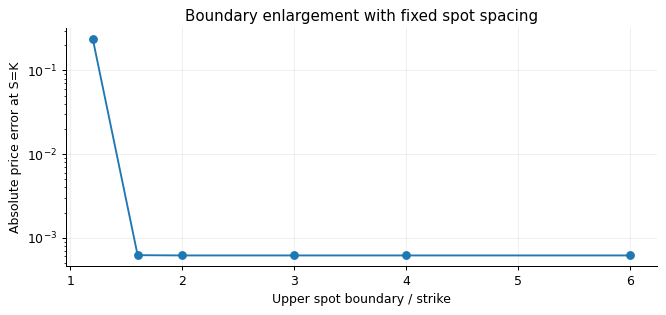

In [11]:
boundary_multiples = (1.2, 1.6, 2.0, 3.0, 4.0, 6.0)
boundary_probe = reference.evaluate(strike)
boundary_rows = []
for multiple in boundary_multiples:
    maximum = multiple * strike
    intervals = round(maximum / (strike / 200))
    solution = pde_pricer.solve(s_max=maximum, n_space=intervals, n_time=800)
    value = solution.evaluate(strike)
    boundary_rows.append((multiple, maximum, intervals, solution.spots[1],
                          value.call_price - boundary_probe.call_price,
                          value.call_delta - boundary_probe.call_delta,
                          value.gamma - boundary_probe.gamma))
table(["Boundary / strike", "Upper boundary", "Spot intervals", "Spacing", "Price error at S=K", "Delta error", "Gamma error"],
      boundary_rows)
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.semilogy(boundary_multiples, [abs(row[4]) for row in boundary_rows], "o-")
ax.set(xlabel="Upper spot boundary / strike", ylabel="Absolute price error at S=K",
       title="Boundary enlargement with fixed spot spacing")
fig.tight_layout()
plt.show()

## Interpretation

- Financial parameter changes alter the option being valued; sample-count and bump changes alter numerical uncertainty or bias.
- The analytical price and Greeks are independent references for these simulation calculations.
- Confidence intervals describe sampling uncertainty under the model and are approximate. Inspect positive-payoff and bump-crossing counts for rare-event diagnostics.
- PDE errors are deterministic discretisation and boundary errors, separate from Monte Carlo sampling uncertainty. Inspect Greeks as well as prices.
- Space, time and domain studies change one numerical choice at a time. Strike alignment, interpolation and locally one-sided rows can affect observed order.
- Run all cells after changing configuration to avoid mixing results from different cases.